## 🏗️ Mini Project

#### Student Study Hours vs Exam Score Predictor

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


np.random.seed(42)
num_students = 50

# 2. Generate random study hours between 0 and 10
study_hours = np.random.uniform(0, 10, num_students)

# 3. Generate random test scores based on study hours (with some noise)
exam_scores = 40 + 5 * study_hours + np.random.normal(0, 5, num_students)

study_hours = study_hours.round(1)
exam_scores = exam_scores.round(1)

# 4. Create a DataFrame
df = pd.DataFrame({'study_hours': study_hours, 'exam_scores': exam_scores})

df.head()

,study_hours,exam_scores
0,3.7,62.4
1,9.5,88.4
2,7.3,76.0
3,6.0,68.4
4,1.6,40.4


In [11]:
df.shape[0]

50

In [12]:
class LinearRegressionScratch:
    def __init__(self, learning_rate = 0.01, epochs = 1000):
        self.lr = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None

    def fit(self,X, y):
        n_samples = X.shape[0]
        self.w = 0
        self.b = 0

        for epoch in range(self.epochs):
            y_pred = self.w *X + self.b

            dw = (-2/n_samples) * np.sum(X *(y- y_pred))
            db = (-2/n_samples) * np.sum(y - y_pred)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X):
        return self.w * X + self.b

Learned w: 4.9
Learned b: 40.39


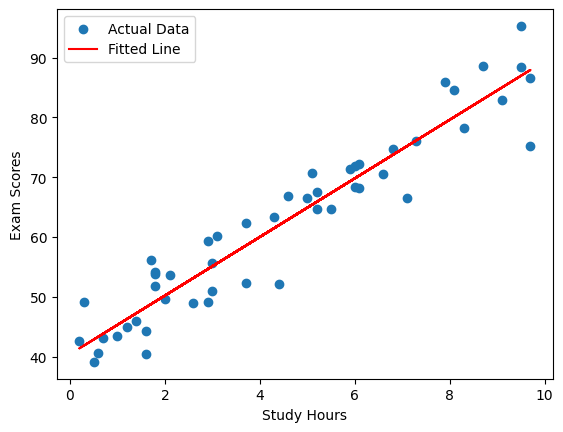

In [13]:
X = df['study_hours'].values
y = df['exam_scores'].values

lr_model = LinearRegressionScratch(learning_rate=0.01, epochs=1000)

lr_model.fit(X, y)

print('Learned w:', lr_model.w.round(2))
print('Learned b:', lr_model.b.round(2))

y_pred = lr_model.predict(X)

plt.scatter(X, y, label='Actual Data')
plt.plot(X, y_pred, color='red', label='Fitted Line')
plt.xlabel('Study Hours')
plt.ylabel('Exam Scores')
plt.legend()
plt.show()

Learned w: 4.85
Learned b: 40.67


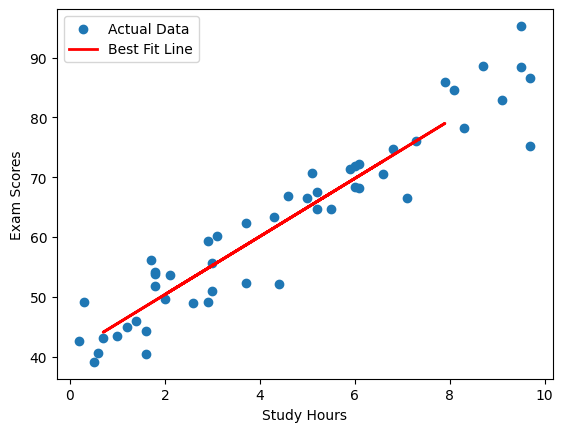

In [14]:
X = df['study_hours'].values.reshape(-1, 1)  # Reshape for sklearn
y = df['exam_scores'].values.reshape(-1, 1)  # Reshape for sklearn

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f'Learned w: {model.coef_[0][0]:.2f}')
print(f'Learned b: {model.intercept_[0]:.2f}')

plt.scatter(X, y, label='Actual Data')
plt.plot(X_test, y_pred, color = 'red', linewidth = 2, label = 'Best Fit Line')
plt.xlabel('Study Hours')
plt.ylabel('Exam Scores')
plt.legend()
plt.show()